In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv("Fraudulent_E-Commerce_Transaction_Data.csv")

In [ ]:
data.head()
#fyi i chose Payment Method to be the categorical column in this dataset to be turned numerical

,Transaction ID,Customer ID,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Customer Location,Device Used,IP Address,Shipping Address,Billing Address,Is Fraudulent,Account Age Days,Transaction Hour
0,15d2e414-8735-46fc-9e02-80b472b2580f,d1b87f62-51b2-493b-ad6a-77e0fe13e785,58.09,2024-02-20 05:58:41,bank transfer,electronics,1,17,Amandaborough,tablet,212.195.49.198,Unit 8934 Box 0058\nDPO AA 05437,Unit 8934 Box 0058\nDPO AA 05437,0,30,5
1,0bfee1a0-6d5e-40da-a446-d04e73b1b177,37de64d5-e901-4a56-9ea0-af0c24c069cf,389.96,2024-02-25 08:09:45,debit card,electronics,2,40,East Timothy,desktop,208.106.249.121,"634 May Keys\nPort Cherylview, NV 75063","634 May Keys\nPort Cherylview, NV 75063",0,72,8
2,e588eef4-b754-468e-9d90-d0e0abfc1af0,1bac88d6-4b22-409a-a06b-425119c57225,134.19,2024-03-18 03:42:55,PayPal,home & garden,2,22,Davismouth,tablet,76.63.88.212,"16282 Dana Falls Suite 790\nRothhaven, IL 15564","16282 Dana Falls Suite 790\nRothhaven, IL 15564",0,63,3
3,4de46e52-60c3-49d9-be39-636681009789,2357c76e-9253-4ceb-b44e-ef4b71cb7d4d,226.17,2024-03-16 20:41:31,bank transfer,clothing,5,31,Lynnberg,desktop,207.208.171.73,"828 Strong Loaf Apt. 646\nNew Joshua, UT 84798","828 Strong Loaf Apt. 646\nNew Joshua, UT 84798",0,124,20
4,074a76de-fe2d-443e-a00c-f044cdb68e21,45071bc5-9588-43ea-8093-023caec8ea1c,121.53,2024-01-15 05:08:17,bank transfer,clothing,2,51,South Nicole,tablet,190.172.14.169,"29799 Jason Hills Apt. 439\nWest Richardtown, ...","29799 Jason Hills Apt. 439\nWest Richardtown, ...",0,158,5


In [4]:
#clean up
data.columns = data.columns.str.strip().str.replace(r'\s+', ' ', regex=True)
data.columns

Index(['Transaction ID', 'Customer ID', 'Transaction Amount',
       'Transaction Date', 'Payment Method', 'Product Category', 'Quantity',
       'Customer Age', 'Customer Location', 'Device Used', 'IP Address',
       'Shipping Address', 'Billing Address', 'Is Fraudulent',
       'Account Age Days', 'Transaction Hour'],
      dtype='str')

In [5]:
data.isna().sum() #looking for missing values

Transaction ID        0
Customer ID           0
Transaction Amount    0
Transaction Date      0
Payment Method        0
Product Category      0
Quantity              0
Customer Age          0
Customer Location     0
Device Used           0
IP Address            0
Shipping Address      0
Billing Address       0
Is Fraudulent         0
Account Age Days      0
Transaction Hour      0
dtype: int64

In [6]:
data.duplicated().sum() # are there any duplicates?

np.int64(0)

In [7]:
# ages of 0 or below are impossible (lowest is -16)
(data['Customer Age'] <= 0).sum()

np.int64(521)

In [8]:
# Transaction ID, Customer ID, IP Address are unique IDs, not features
# Transaction Date is a raw date text
# Customer Location, there are 99,135 different town names, too many to use
# Shipping Address, Billing Address, free text
# Product Category, Device Used, only one categorical column can be converted, and I chose Payment Method
data = data.drop(columns = ['Transaction ID', 'Customer ID', 'Transaction Date', 'Customer Location',
                            'IP Address', 'Shipping Address', 'Billing Address',
                            'Product Category', 'Device Used'])
data = data[data['Customer Age'] > 0]   # remove the 521 impossible ages
data.shape

(1472431, 7)

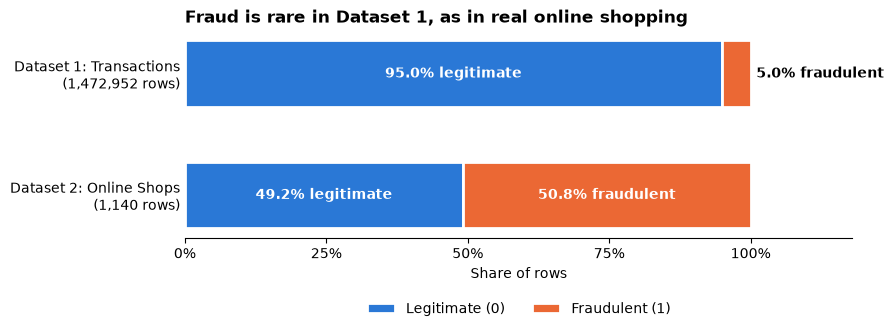

In [ ]:
rows = [('Dataset 1: Transactions\n(1,472,952 rows)', 1399114, 73838),
        ('Dataset 2: Online Shops\n(1,140 rows)', 561, 579)]

fig, ax = plt.subplots(figsize = (9, 3.6))
for y, (name, legit, fraud) in zip([1, 0], rows):
    lp, fp = legit / (legit + fraud) * 100, fraud / (legit + fraud) * 100
    ax.barh(y, lp, height = 0.55, color = '#2a78d6', edgecolor = 'white', linewidth = 2, label = 'Legitimate (0)' if y == 1 else None)
    ax.barh(y, fp, left = lp, height = 0.55, color = '#eb6834', edgecolor = 'white', linewidth = 2, label = 'Fraudulent (1)' if y == 1 else None)
    ax.text(lp / 2, y, f'{lp:.1f}% legitimate', ha = 'center', va = 'center', color = 'white', fontweight = 'bold')
    if fp > 10: ax.text(lp + fp / 2, y, f'{fp:.1f}% fraudulent', ha = 'center', va = 'center', color = 'white', fontweight = 'bold')
    else: ax.text(101, y, f'{fp:.1f}% fraudulent', va = 'center', fontweight = 'bold')

ax.set_yticks([1, 0], [r[0] for r in rows])
ax.set_xlim(0, 118); ax.set_xticks([0, 25, 50, 75, 100], ['0%', '25%', '50%', '75%', '100%']); ax.set_xlabel('Share of rows')
for s in ['top', 'right', 'left']: ax.spines[s].set_visible(False)
ax.tick_params(axis = 'y', length = 0)
ax.legend(loc = 'upper center', bbox_to_anchor = (0.5, -0.25), ncol = 2, frameon = False)
ax.set_title('Fraud is rare in Dataset 1, as in real online shopping', loc = 'left', fontweight = 'bold')
plt.tight_layout()
#plt.savefig('fig_class_balance_both.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [10]:
# there are 1.47M rows, which is too many, lets take a sample
data = data.sample(50000, random_state = 42).reset_index(drop = True)
data['Is Fraudulent'].value_counts()

Is Fraudulent
0    47470
1     2530
Name: count, dtype: int64

In [11]:
data.dtypes   # payment Method is the only text column left

Transaction Amount    float64
Payment Method            str
Quantity                int64
Customer Age            int64
Is Fraudulent           int64
Account Age Days        int64
Transaction Hour        int64
dtype: object

In [12]:
all_paymethods = sorted(set(data['Payment Method']))
all_paymethods

['PayPal', 'bank transfer', 'credit card', 'debit card']

In [13]:
one_hot_encoded_data = pd.DataFrame(0, index = data.index, columns = all_paymethods)

for index, row in data.iterrows():
    one_hot_encoded_data.at[index, row['Payment Method']] = 1

one_hot_encoded_data

,PayPal,bank transfer,credit card,debit card
0,0,1,0,0
1,0,0,0,1
2,0,0,1,0
3,0,1,0,0
4,0,1,0,0
...,...,...,...,...
49995,0,1,0,0
49996,0,0,1,0
49997,0,1,0,0
49998,0,0,1,0


In [14]:
data = pd.concat([data.drop(columns = ['Payment Method']), one_hot_encoded_data], axis = 1)
data.shape

(50000, 10)

In [15]:
column = data.columns[data.columns != 'Is Fraudulent']
column

Index(['Transaction Amount', 'Quantity', 'Customer Age', 'Account Age Days',
       'Transaction Hour', 'PayPal', 'bank transfer', 'credit card',
       'debit card'],
      dtype='str')

In [16]:
#scaling
data_scale = data[column]
scaler = StandardScaler()
scaled = scaler.fit_transform(data_scale)
data_scale[column] = scaled
data_scale.describe().loc[['mean', 'std']].round(2)

,Transaction Amount,Quantity,Customer Age,Account Age Days,Transaction Hour,PayPal,bank transfer,credit card,debit card
mean,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [17]:
#splitting
X = data_scale
y = data['Is Fraudulent']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(), y_test.value_counts())

(40000, 9) (10000, 9)
Is Fraudulent
0    37976
1     2024
Name: count, dtype: int64 Is Fraudulent
0    9494
1     506
Name: count, dtype: int64


In [ ]:
#example from class
models = {'Support Vector': SVC(random_state = 42),
          'Naive Bayes': GaussianNB(),
          'KNN': KNeighborsClassifier(n_neighbors = 5),
          'Logistic Regression': LogisticRegression(max_iter = 1000)}

In [19]:
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)      # training
    pred = model.predict(X_test)     # testing

    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    results[name] = {'Accuracy': accuracy_score(y_test, pred),
                     'Precision': precision_score(y_test, pred, zero_division = 0),
                     'Recall': recall_score(y_test, pred),
                     'Specificity': tn / (tn + fp),   # sklearn has no specificity function
                     'F1': f1_score(y_test, pred)}
    print(name, '| TN:', tn, 'FP:', fp, 'FN:', fn, 'TP:', tp)

results_d1 = pd.DataFrame(results).T.round(3)
results_d1

Support Vector | TN: 9487 FP: 7 FN: 455 TP: 51
Naive Bayes | TN: 9319 FP: 175 FN: 405 TP: 101
KNN | TN: 9445 FP: 49 FN: 440 TP: 66
Logistic Regression | TN: 9485 FP: 9 FN: 453 TP: 53


,Accuracy,Precision,Recall,Specificity,F1
Support Vector,0.954,0.879,0.101,0.999,0.181
Naive Bayes,0.942,0.366,0.200,0.982,0.258
KNN,0.951,0.574,0.130,0.995,0.213
Logistic Regression,0.954,0.855,0.105,0.999,0.187


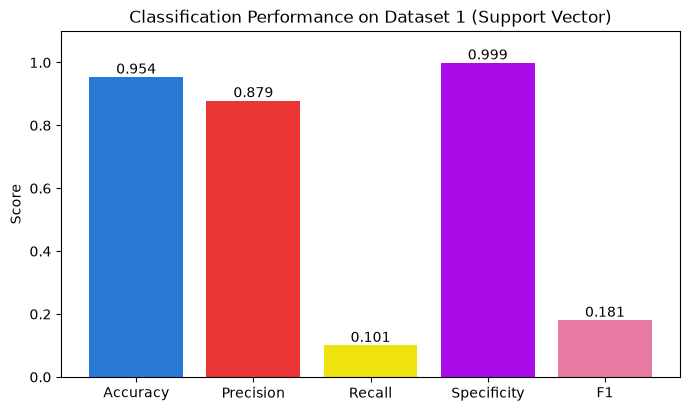

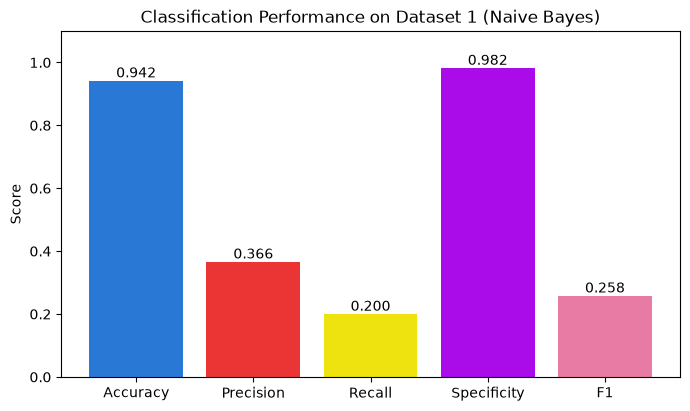

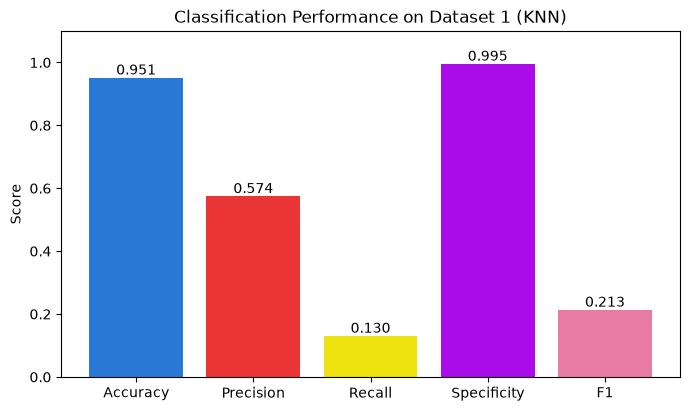

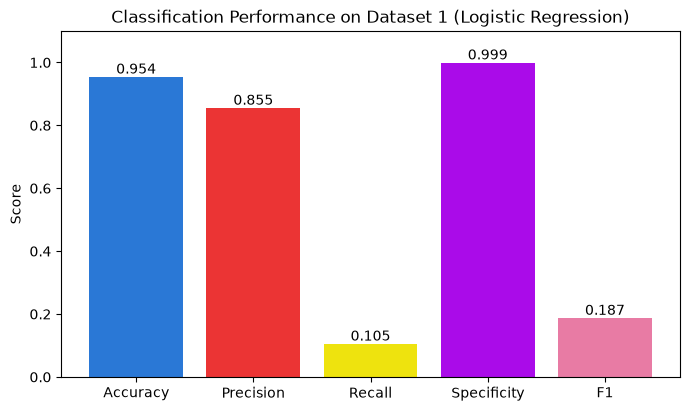

In [ ]:
colors = ['#2a78d6', "#eb3434", "#eee30e", "#aa0be9", '#e87ba4']

for name in results_d1.index:
    scores = results_d1.loc[name]

    plt.figure(figsize = (7, 4))
    bars = plt.bar(scores.index, scores.values, color = colors)
    plt.bar_label(bars, fmt = '%.3f')
    plt.ylim(0, 1.1)
    plt.ylabel('Score')
    plt.tight_layout()
    plt.title(f'Classification Performance on Dataset 1 ({name})')
    #plt.savefig(f'd1_{name}.png', dpi=150, bbox_inches='tight')
    plt.show()